In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.to_csv("../data/titanic.csv", index=False)

print("Dataset saved successfully.")

Dataset saved successfully.


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape:
(891, 12)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
0


In [8]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
0


In [9]:
print("\nData Types:")
print(df.dtypes)


Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


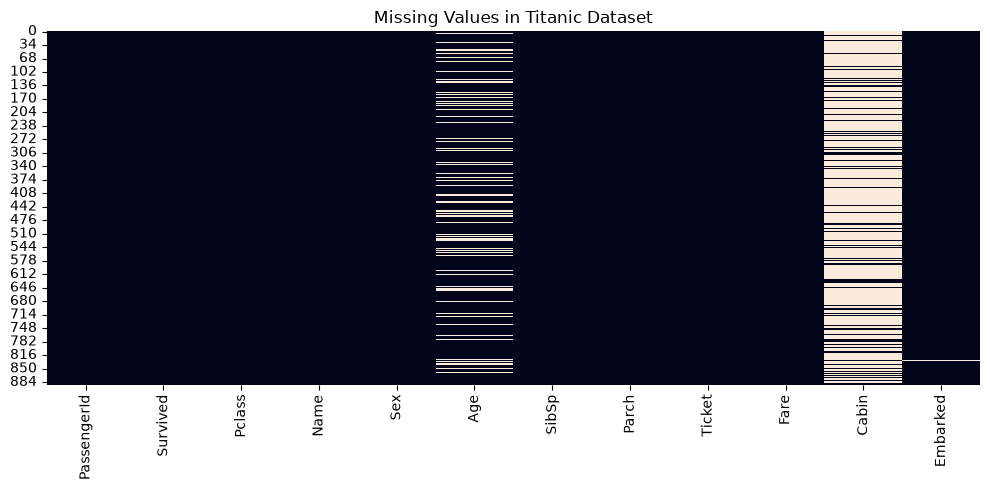

In [10]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Titanic Dataset")
plt.tight_layout()

plt.savefig("../outputs/missing_values.png")
plt.show()

In [11]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [12]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [13]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [14]:
df.drop("Cabin", axis=1, inplace=True)

In [15]:
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [16]:
df.drop(["Name", "Ticket"], axis=1, inplace=True)
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.0,1,0,7.2500,S
1,2,1,1,female,38.0,1,0,71.2833,C
2,3,1,3,female,26.0,0,0,7.9250,S
3,4,1,1,female,35.0,1,0,53.1000,S
4,5,0,3,male,35.0,0,0,8.0500,S


In [17]:
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Sex                str
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked           str
dtype: object


In [18]:
X = df.drop("Survived", axis=1)
y = df["Survived"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   PassengerId  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0            1       3    male  22.0      1      0   7.2500        S
1            2       1  female  38.0      1      0  71.2833        C
2            3       3  female  26.0      0      0   7.9250        S
3            4       1  female  35.0      1      0  53.1000        S
4            5       3    male  35.0      0      0   8.0500        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [19]:
categorical_features = ["Sex", "Embarked"]

numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [21]:
X_processed = preprocessor.fit_transform(X)

print("Preprocessing completed.")
print("Processed data shape:", X_processed.shape)

Preprocessing completed.
Processed data shape: (891, 10)


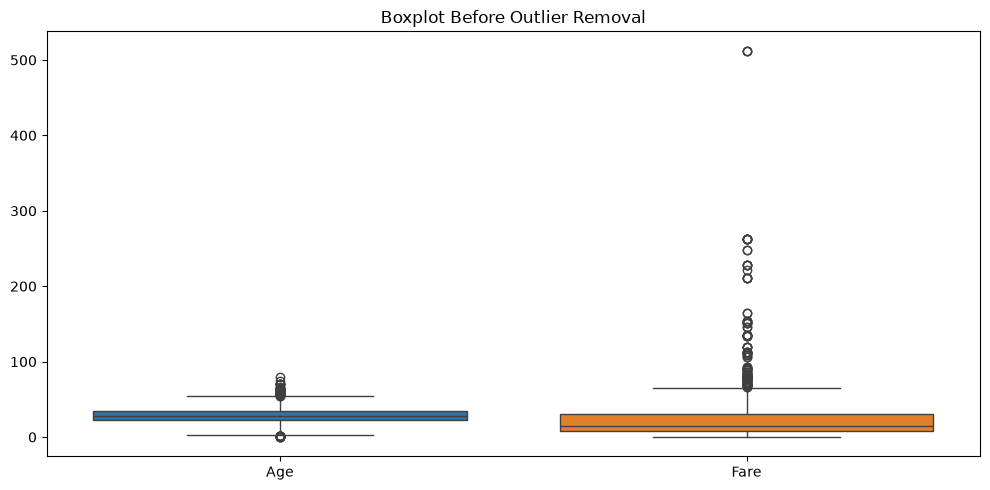

In [22]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df[["Age", "Fare"]])

plt.title("Boxplot Before Outlier Removal")
plt.tight_layout()

plt.savefig("../outputs/before_outlier_removal.png")
plt.show()

In [23]:
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return data[
        (data[column] >= lower_bound) &
        (data[column] <= upper_bound)
    ]

In [24]:
df_clean = remove_outliers_iqr(df, "Fare")

print("Original dataset shape:", df.shape)
print("After outlier removal:", df_clean.shape)

Original dataset shape: (891, 9)
After outlier removal: (775, 9)


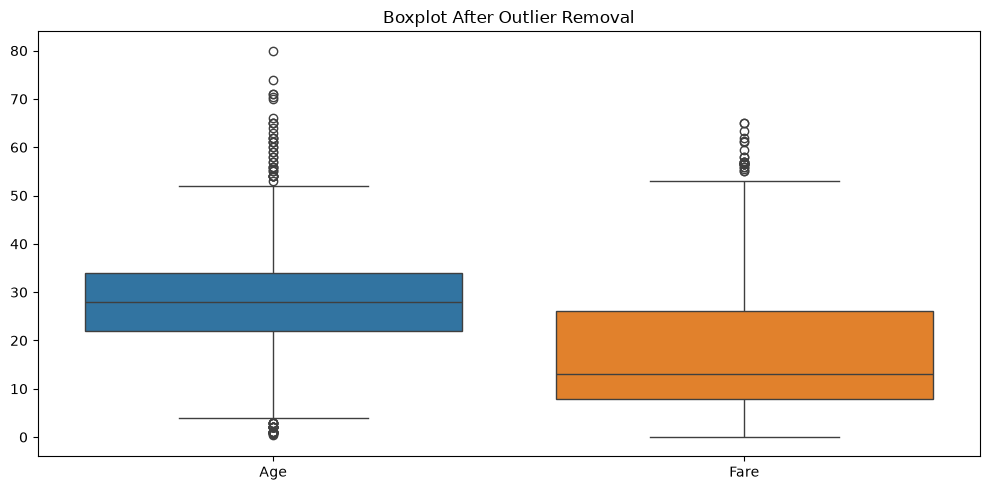

In [25]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_clean[["Age", "Fare"]])

plt.title("Boxplot After Outlier Removal")
plt.tight_layout()

plt.savefig("../outputs/after_outlier_removal.png")
plt.show()

In [26]:
print("FINAL DATASET INFORMATION")
print("-------------------------")

print("Shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst five rows:")
display(df_clean.head())

FINAL DATASET INFORMATION
-------------------------
Shape: (775, 9)

Missing values:
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Sex                str
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked           str
dtype: object

First five rows:


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,male,22.0,1,0,7.2500,S
2,3,1,3,female,26.0,0,0,7.9250,S
3,4,1,1,female,35.0,1,0,53.1000,S
4,5,0,3,male,35.0,0,0,8.0500,S
5,6,0,3,male,28.0,0,0,8.4583,Q


In [27]:
df_clean.to_csv("../data/titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
